In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
df=pd.read_csv("applicants_cleaned.csv",parse_dates=['Application Date'])
df.head()

,Applicant Name,Email,Phone,Domain Applied,University,Application Date,Status
0,Zara Gul,zara_gul@yahoo.com,+923247378578,Data Science,FAST,2026-01-08,Selected
1,"""Usman """,not_provide@gmail.com,+923089435402,Mobile Application,IBA,2026-09-27,Under Review
2,Hira Hassan,Hira@hotmail.com,03132424292,Web Development,LUMS,2026-06-01,Under Review
3,Amna Ahmed,Amna.Ahmed@gmail.com,03224421855,Data Science,FAST-NU,2026-02-01,Selected
4,"""Imran """,not_provide@gmail.com,03332360321,UI/UX,LUMS,2026-05-16,Selected


Week 2 — Exploratory Data Analysis: NextGenLearners Applicant Insights

In [5]:
df.info()
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 950 entries, 0 to 949
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Applicant Name    950 non-null    str           
 1   Email             950 non-null    str           
 2   Phone             950 non-null    str           
 3   Domain Applied    950 non-null    str           
 4   University        950 non-null    str           
 5   Application Date  950 non-null    datetime64[us]
 6   Status            950 non-null    str           
dtypes: datetime64[us](1), str(6)
memory usage: 119.8 KB


,Applicant Name,Email,Phone,Domain Applied,University,Application Date,Status
0,Zara Gul,zara_gul@yahoo.com,+923247378578,Data Science,FAST,2026-01-08,Selected
1,"""Usman """,not_provide@gmail.com,+923089435402,Mobile Application,IBA,2026-09-27,Under Review
2,Hira Hassan,Hira@hotmail.com,03132424292,Web Development,LUMS,2026-06-01,Under Review
3,Amna Ahmed,Amna.Ahmed@gmail.com,03224421855,Data Science,FAST-NU,2026-02-01,Selected
4,"""Imran """,not_provide@gmail.com,03332360321,UI/UX,LUMS,2026-05-16,Selected


In [6]:
count_domains=df['Domain Applied'].value_counts()
print(count_domains)

Domain Applied
Mobile Application         249
Artificial Intelligence    237
Data Science               213
Web Development            129
UI/UX                      122
Name: count, dtype: int64


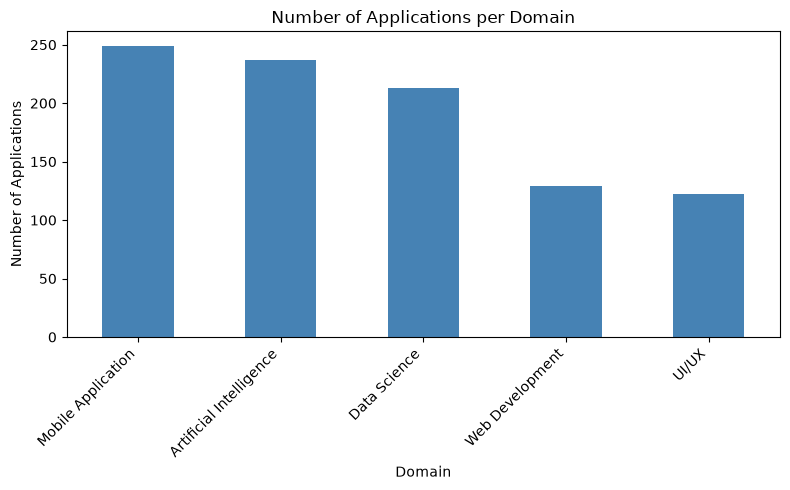

In [7]:
plt.figure(figsize=(8,5)) 
count_domains.plot(kind='bar', color='steelblue') 
plt.title('Number of Applications per Domain') 
plt.xlabel('Domain') 
plt.ylabel('Number of Applications')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show() 

In [8]:
df['Application Month'] = df['Application Date'].dt.to_period('M')
monthly_trend = df.groupby('Application Month').size() 
print(monthly_trend) 

Application Month
2026-01     98
2026-02     85
2026-03    106
2026-04     98
2026-05    124
2026-06     88
2026-07    100
2026-08    100
2026-09     98
2026-10     53
Freq: M, dtype: int64


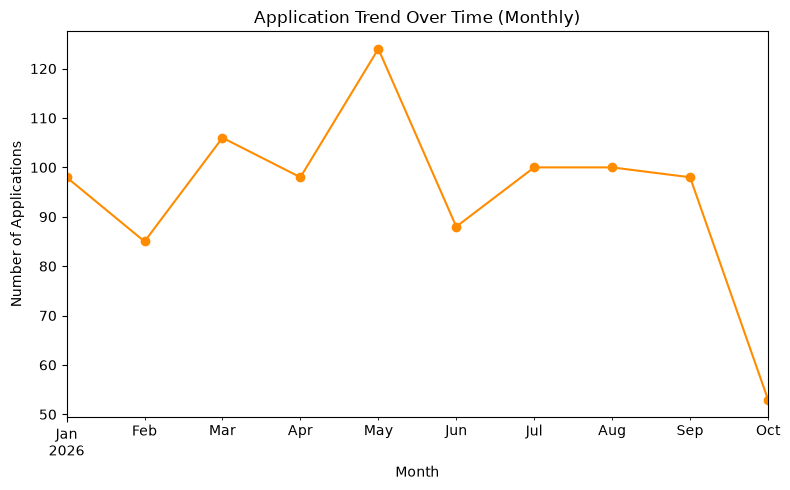

In [10]:
plt.figure(figsize=(8,5))
monthly_trend.plot(kind='line', marker='o', color='darkorange') 
plt.title('Application Trend Over Time (Monthly)') 
plt.xlabel('Month')
plt.ylabel('Number of Applications') 
plt.tight_layout()
plt.show()

In [11]:
status_counts = df['Status'].value_counts()
print(status_counts) 

Status
Selected        370
Under Review    337
Rejected        243
Name: count, dtype: int64


In [14]:
status_by_domain = pd.pivot_table(
    df,
    index='Domain Applied',
    columns='Status',
    values='Applicant Name',
    aggfunc='count',
    fill_value=0
)
print(status_by_domain)


Status                   Rejected  Selected  Under Review
Domain Applied                                           
Artificial Intelligence        61        88            88
Data Science                   55        84            74
Mobile Application             57       112            80
UI/UX                          35        42            45
Web Development                35        44            50


In [16]:
status_by_domain_pct = status_by_domain.div(status_by_domain.sum(axis=1), axis=0) * 100 
print(status_by_domain_pct.round(1)) 

Status                   Rejected  Selected  Under Review
Domain Applied                                           
Artificial Intelligence      25.7      37.1          37.1
Data Science                 25.8      39.4          34.7
Mobile Application           22.9      45.0          32.1
UI/UX                        28.7      34.4          36.9
Web Development              27.1      34.1          38.8


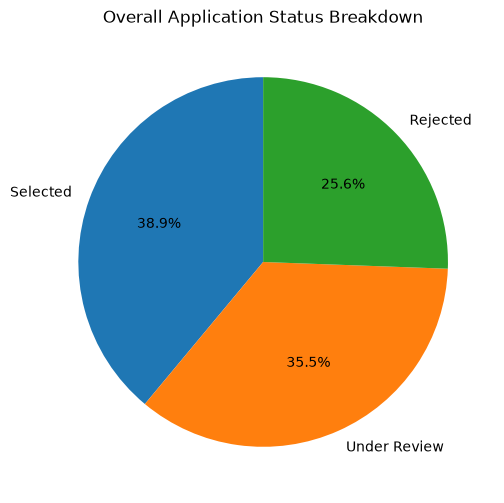

In [17]:
plt.figure(figsize=(6,6)) 
status_counts.plot(kind='pie', autopct='%1.1f%%', startangle=90) 
plt.title('Overall Application Status Breakdown') 
plt.show() 

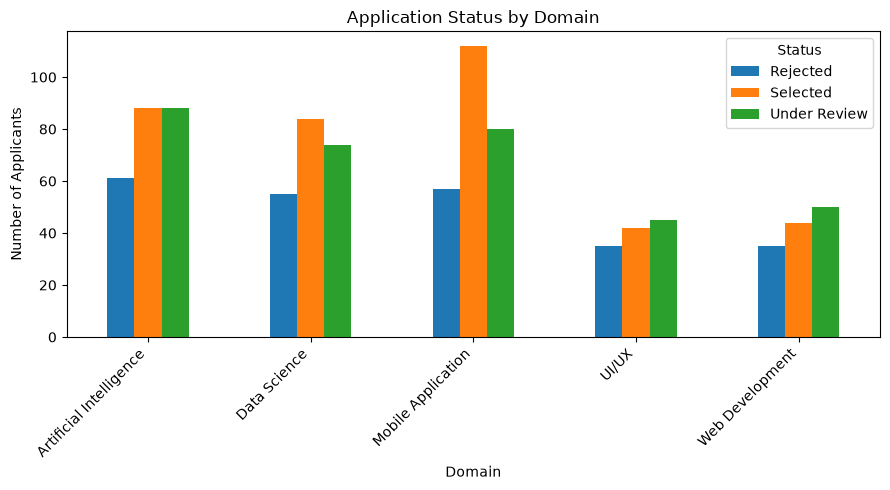

In [22]:
status_by_domain.plot(kind='bar', figsize=(9,5)) 
plt.title('Application Status by Domain') 
plt.xlabel('Domain') 
plt.ylabel('Number of Applicants') 
plt.xticks(rotation=45, ha='right') 
plt.legend(title='Status') 
plt.tight_layout() 
plt.show() 

In [23]:
top_universities = df['University'].value_counts().head(10) 
print(top_universities) 

University
FAST-NU               113
UoK                   107
FAST                  102
Karachi University    101
IBA                   100
NED                   100
NUST                   93
LUMS                   90
NUCES                  86
Not Specified          58
Name: count, dtype: int64


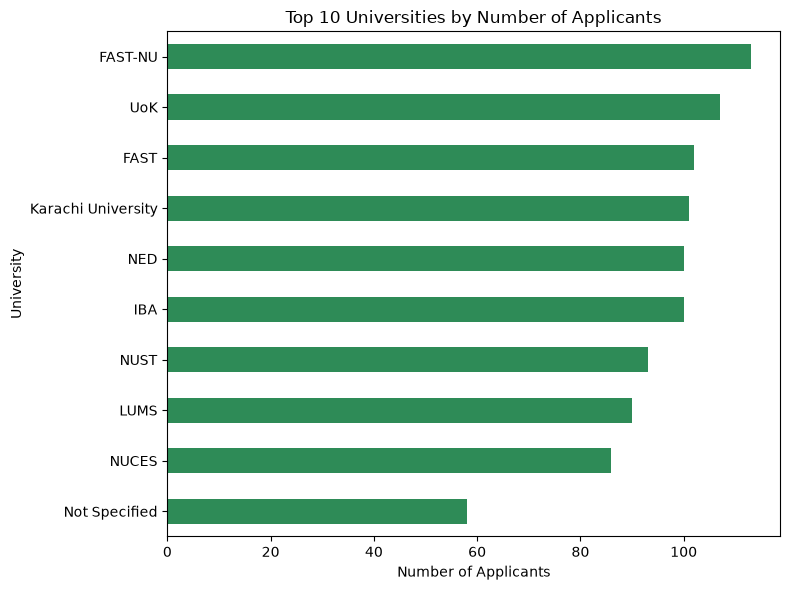

In [24]:
plt.figure(figsize=(8,6)) 
top_universities.sort_values().plot(kind='barh', color='seagreen') 
plt.title('Top 10 Universities by Number of Applicants') 
plt.xlabel('Number of Applicants') 
plt.ylabel('University') 
plt.tight_layout() 
plt.show() 

### Step 7: Bonus Chart — Application Submission Trends by Day of the Week

> **Why this question?** 
> I wanted to explore whether applicants predominantly submit their applications during busy weekdays or wait until their free time on weekends, which helps determine the most effective timing for reminder emails and social media campaigns.

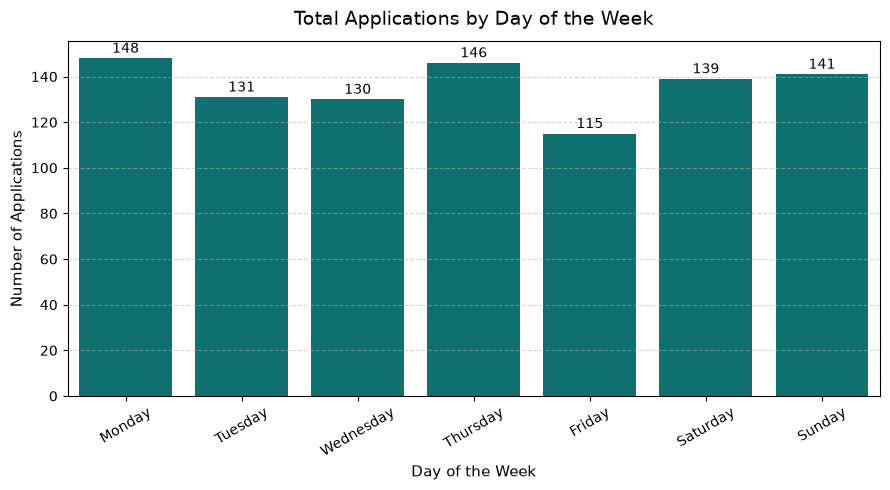

In [31]:
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
applications_by_day = df['Application Date'].dt.day_name().value_counts().reindex(day_order)

plt.figure(figsize=(9, 5))
sns.barplot(x=applications_by_day.index, y=applications_by_day.values, color='teal')

plt.title('Total Applications by Day of the Week', fontsize=14, pad=12)
plt.xlabel('Day of the Week', fontsize=11)
plt.ylabel('Number of Applications', fontsize=11)
plt.xticks(rotation=30)
plt.grid(axis='y', linestyle='--', alpha=0.5)

for idx, val in enumerate(applications_by_day.values):
    plt.text(idx, val + 1, str(val), ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

## Key Insights

- **Mobile Application and AI lead domain interest:** Mobile Application received the highest number of submissions at 249 applications[cite: 1], closely followed by Artificial Intelligence (237)[cite: 1] and Data Science (213)[cite: 1]. Web Development (129)[cite: 1] and UI/UX (122)[cite: 1] recorded the lowest volumes across the cohort[cite: 1].
- **Recruitment activity peaked in May 2026:** Application volume remained consistent from January through April (averaging 85–106 per month)[cite: 1], surged to an annual high of 124 in May[cite: 1], and steadily tapered off to a low of 53 by October[cite: 1]. This indicates that initial mid-year marketing campaigns yielded the highest return[cite: 1].
- **Overall cohort status distribution:** Out of 950 total applicants[cite: 1], 370 candidates were Selected (~38.9%)[cite: 1], 337 remain Under Review (~35.5%)[cite: 1], and 243 were Rejected (~25.6%)[cite: 1].
- **Selection rate varies significantly by domain:** Despite having the highest competition, Mobile Application sustained the highest acceptance rate at 45.0% (112 selected)[cite: 1], followed by Data Science at 39.4%[cite: 1] and Artificial Intelligence at 37.1%[cite: 1]. UI/UX (34.4%)[cite: 1] and Web Development (34.1%)[cite: 1] observed the lowest selection rates[cite: 1]. Rejection rates stayed relatively balanced across all fields, ranging between 22.9% and 28.7%[cite: 1].
- **High concentration across top institutions:** Applicant volume is heavily concentrated in a small group of universities[cite: 1]. FAST-NU (113)[cite: 1], UoK (107)[cite: 1], FAST (102)[cite: 1], Karachi University (101)[cite: 1], IBA (100)[cite: 1], and NED (100)[cite: 1] make up the majority of the applicant base, highlighting the primary campuses for targeted future ambassador and recruitment drives[cite: 1].